# NLP Lab 4 — Word Embeddings and Vector Representation

**Requirements:** `numpy`, `matplotlib`, `spacy`, `scikit-learn`, `scipy`, `nltk` and `gensim`.
No model downloads, no GPU, no internet access.

> **About the data:** this lab uses a **synthetic** corpus generated inside the notebook.
> It contains no personal data. Part 10 deliberately injects a skew into a *separate*
> corpus purely to demonstrate how bias measurement works.

---
# Part 0 — Setup

In [125]:
# If you are on Google Colab, uncomment the next line
%pip install -q spacy gensim scikit-learn nltk scipy

Note: you may need to restart the kernel to use updated packages.


In [126]:
import math
import random
import time
from collections import Counter

import numpy as np
import spacy
from scipy import sparse
from nltk.util import skipgrams
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from gensim import matutils
from gensim.corpora import Dictionary
from gensim.models import TfidfModel, Word2Vec, KeyedVectors
from gensim.models.callbacks import CallbackAny2Vec

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

np.set_printoptions(precision=3, suppress=True, linewidth=120)

import gensim, sklearn
print("Ready — numpy", np.__version__, "| spacy", spacy.__version__,
      "| scikit-learn", sklearn.__version__, "| gensim", gensim.__version__)

Ready — numpy 2.5.3 | spacy 3.8.16 | scikit-learn 1.9.1 | gensim 4.4.0


## 0.1 Tokenizer (spaCy)

In [127]:
nlp = spacy.blank("en")          # tokenizer only — no pipeline, no download


def tokenize(text):
    """spaCy tokenization, lowercased, alphabetic tokens only (punctuation is dropped)."""
    return [t.lower_ for t in nlp(text) if t.is_alpha]


print(tokenize("A student drinks coffee at breakfast."))

['a', 'student', 'drinks', 'coffee', 'at', 'breakfast']


## 0.2 The corpus

A synthetic corpus built from sentence templates, so that it is:

- **regular enough** that vectors can learn something in a few seconds
- **structured in a way we can verify** — words of the same semantic class appear in the same contexts

The sentences are deliberately terse (no articles). Function words push related words apart,
and with a context window of ±2 that would hide the very patterns we want to observe.

> The word **"apple"** appears in *two senses* on purpose (the fruit, and the technology
> company). Part 11 uses it to show the central limitation of static embeddings.

In [128]:
PERSON = ["pupil", "student", "lecturer", "teacher", "doctor", "nurse",
          "engineer", "chef", "programmer"]
FOOD   = ["rice", "noodles", "salad", "cake", "omelette", "soup"]
DRINK  = ["coffee", "tea", "milk", "juice", "water"]
PLACE  = ["school", "university", "hospital", "market", "restaurant", "factory"]

WORKPLACE = {
    "pupil":      "school",     "student":    "university",
    "teacher":    "school",     "lecturer":   "university",
    "doctor":     "hospital",   "nurse":      "hospital",
    "engineer":   "factory",    "chef":       "restaurant",
    "programmer": "office",
}


def generate_corpus(n_sentences=3000, seed=RANDOM_SEED):
    rng = random.Random(seed)

    def place_for(p):
        # people are at their own workplace 90% of the time -
        # this is the signal the vectors have to pick up
        return WORKPLACE[p] if rng.random() < 0.9 else rng.choice(PLACE)

    out = []
    for _ in range(n_sentences):
        r = rng.random()
        p = rng.choice(PERSON)
        if r < 0.20:
            out.append(f"{p} eats {rng.choice(FOOD)} at {place_for(p)}")
        elif r < 0.38:
            out.append(f"{p} drinks {rng.choice(DRINK)} at breakfast")
        elif r < 0.56:
            out.append(f"{p} visits {place_for(p)} daily")
        elif r < 0.68:
            out.append(f"{p} works at {WORKPLACE[p]}")
        elif r < 0.76:
            out.append(f"{p} likes {rng.choice(FOOD)} very much")
        elif r < 0.84:
            out.append(f"{p} buys {rng.choice(DRINK)} at market")
        elif r < 0.90:
            out.append(f"{rng.choice(FOOD)} at {rng.choice(PLACE)} tastes great")
        elif r < 0.95:
            # "apple" in its *fruit* sense
            out.append(f"{p} eats apple at {rng.choice(['market', 'restaurant'])}")
        else:
            # "apple" in its *company* sense
            out.append(rng.choice([
                "company apple sells smartphones",
                "apple launches iphone in america",
                "apple and samsung sell smartphones",
                "customer buys iphone at store",
            ]))
    return out


corpus_raw = generate_corpus()
corpus = [tokenize(s) for s in corpus_raw]

print("sentences :", len(corpus))
print("tokens    :", sum(len(s) for s in corpus))
for s in corpus[:5]:
    print("  ", s)

sentences : 3000
tokens    : 14033
   ['pupil', 'works', 'at', 'school']
   ['teacher', 'likes', 'noodles', 'very', 'much']
   ['student', 'eats', 'soup', 'at', 'university']
   ['engineer', 'visits', 'factory', 'daily']
   ['teacher', 'eats', 'omelette', 'at', 'school']


## 0.3 Vocabulary

Drop words seen fewer than `MIN_COUNT` times: a word observed a handful of times gets a
badly estimated vector. (The original `word2vec` uses `min_count=5`.)

In [129]:
MIN_COUNT = 5

token_counts = Counter(w for sent in corpus for w in sent)
vocab   = sorted([w for w, c in token_counts.items() if c >= MIN_COUNT])
word2id = {w: i for i, w in enumerate(vocab)}
id2word = {i: w for w, i in word2id.items()}
V = len(vocab)

# sentences as index lists (words outside the vocabulary are dropped)
corpus_ids = [[word2id[w] for w in sent if w in word2id] for sent in corpus]

print("vocabulary size |V| =", V)
print("\n10 most frequent words:")
for w, c in token_counts.most_common(10):
    print(f"   {w:<14} {c}")

vocabulary size |V| = 53

10 most frequent words:
   at             2069
   eats           738
   visits         556
   daily          556
   drinks         518
   breakfast      518
   university     371
   works          370
   hospital       350
   school         345


---
# Cosine similarity

**Libraries:** `sklearn.metrics.pairwise.cosine_similarity` computes the formula (and returns 0
for a zero vector instead of `nan`). 

For nearest-neighbour search we wrap any matrix in a
**gensim `KeyedVectors`** object, which gives us `.most_similar()`, `.similarity()` and
analogies for free — the same API you will use on real pretrained vectors.

### cosine similarity and a nearest-neighbour index

In [130]:
def cosine(u, v):
    """Cosine similarity of two 1-D vectors, using sklearn's cosine_similarity.
    cosine_similarity expects 2-D input, so reshape u and v to (1, d)."""
    return float(cosine_similarity(np.reshape(u, (1, -1)), np.reshape(v, (1, -1)))[0, 0])


def to_kv(E, id2word):
    """
        Wrap a matrix E of shape (|V|, d) (row i = vector of id2word[i]) in a gensim KeyedVectors,
        so that kv.most_similar(word, topn=5) works on it.
        kv = KeyedVectors(vector_size=d) ; kv.add_vectors(list_of_words, E.astype(np.float32))
        """
    kv = KeyedVectors(vector_size=E.shape[1])
    kv.add_vectors([id2word[i] for i in range(E.shape[0])], np.asarray(E, dtype=np.float32))
    return kv

# 🔍 Check
assert abs(cosine(np.array([1.0, 0.0]), np.array([1.0, 0.0])) - 1.0) < 1e-12
assert abs(cosine(np.array([1.0, 0.0]), np.array([0.0, 1.0])) - 0.0) < 1e-12
assert abs(cosine(np.array([1.0, 0.0]), np.array([-1.0, 0.0])) + 1.0) < 1e-12
assert cosine(np.zeros(3), np.ones(3)) == 0.0

# In one-hot space every cosine is 0, so nothing can be ranked
kv_onehot = to_kv(np.eye(V), id2word)
print("\nNearest neighbours of 'rice' in one-hot space:")
for w, s in kv_onehot.most_similar("rice", topn=5):
    print(f"   {w:<14} {s:.4f}")
print("=> every score is exactly 0.0000. The ranking you see is arbitrary.")


Nearest neighbours of 'rice' in one-hot space:
   america        0.0000
   apple          0.0000
   and            0.0000
   breakfast      0.0000
   buys           0.0000
=> every score is exactly 0.0000. The ranking you see is arbitrary.


---
# Term–document matrix and TF-IDF

In [131]:
DOCS_RAW = [
    "restaurant sells noodles and salad. noodles at restaurant taste great.",
    "student studies at university daily. lecturer teaches student at university.",
    "doctor and nurse work at hospital. doctor examines patient at hospital daily.",
    "company apple sells smartphones. iphone is a smartphone at store, sells well.",
]
DOC_NAMES = ["D1:food", "D2:study", "D3:health", "D4:tech"]

docs_tokens = [tokenize(d) for d in DOCS_RAW]

for name, toks in zip(DOC_NAMES, docs_tokens):
    print(f"{name:<11}", toks)
print("\nThis part has its own vocabulary: these four documents use words the main corpus lacks.")

D1:food     ['restaurant', 'sells', 'noodles', 'and', 'salad', 'noodles', 'at', 'restaurant', 'taste', 'great']
D2:study    ['student', 'studies', 'at', 'university', 'daily', 'lecturer', 'teaches', 'student', 'at', 'university']
D3:health   ['doctor', 'and', 'nurse', 'work', 'at', 'hospital', 'doctor', 'examines', 'patient', 'at', 'hospital', 'daily']
D4:tech     ['company', 'apple', 'sells', 'smartphones', 'iphone', 'is', 'a', 'smartphone', 'at', 'store', 'sells', 'well']

This part has its own vocabulary: these four documents use words the main corpus lacks.


### build the term–document matrix

https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html

In [132]:
def build_term_doc(docs_raw):
    """
        Return (TD, vectorizer):
          TD         : dense array of shape (|V|, N) - entry [i, j] = count of word i in document j
          vectorizer : the fitted sklearn CountVectorizer
        Use CountVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None) so that it uses
        our spaCy tokenizer. Careful: CountVectorizer returns (N, |V|) - transpose it.
        """
    vectorizer = CountVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None)
    X = vectorizer.fit_transform(docs_raw)            # sparse (N, |V|)
    return X.T.toarray().astype(float), vectorizer


TD, count_vec = build_term_doc(DOCS_RAW)
print("term-document matrix shape =", TD.shape, "\n")

doc_vocab = list(count_vec.get_feature_names_out())
doc_w2i   = {w: i for i, w in enumerate(doc_vocab)}
doc_i2w   = {i: w for w, i in doc_w2i.items()}
print("vocabulary of this document set =", len(doc_vocab), "\n")

show = ["noodles", "student", "doctor", "smartphones", "at", "daily"]
print(f"{'word':<14}" + "".join(f"{n:>12}" for n in DOC_NAMES))
for w in show:
    print(f"{w:<14}" + "".join(f"{v:>12.0f}" for v in TD[doc_w2i[w]]))

# 🔍 Check
assert TD.shape == (len(doc_vocab), len(DOCS_RAW))
assert TD.sum() == sum(len(t) for t in docs_tokens)
assert TD[doc_w2i["noodles"], 0] == 2


term-document matrix shape = (29, 4) 

vocabulary of this document set = 29 

word               D1:food    D2:study   D3:health     D4:tech
noodles                  2           0           0           0
student                  0           2           0           0
doctor                   0           0           2           0
smartphones              0           0           0           1
at                       1           2           2           1
daily                    0           1           1           0


In [133]:
def tf_idf(docs_tokens, doc_vocab):
    """
        Return the TF-IDF matrix of shape (|V|, N), rows in the order of `doc_vocab`, using gensim:
          dct   = Dictionary(docs_tokens)
          bow   = [dct.doc2bow(d) for d in docs_tokens]
          model = TfidfModel(bow, wlocal=..., wglobal=..., normalize=False)
                    wlocal  : tf array        -> 1 + log10(tf)
                    wglobal : (df, N) scalars -> log10(N / df)
          dense = matutils.corpus2dense(model[bow], num_terms=len(dct))   # rows follow dct.token2id
        then reorder the rows with dct.token2id so they match doc_vocab.
        """
    dct = Dictionary(docs_tokens)
    bow = [dct.doc2bow(d) for d in docs_tokens]
    model = TfidfModel(bow,
                       wlocal=lambda tf: 1.0 + np.log10(tf),
                       wglobal=lambda df, n: math.log10(n / df),
                       normalize=False)
    dense = matutils.corpus2dense(model[bow], num_terms=len(dct))
    return dense[[dct.token2id[w] for w in doc_vocab]].astype(float)


TFIDF = tf_idf(docs_tokens, doc_vocab)
print("\nTF-IDF matrix shape =", TFIDF.shape, "\n")
print("TF-IDF values for the word noodles in each document:")
print(TFIDF[doc_w2i["noodles"]])


TF-IDF matrix shape = (29, 4) 

TF-IDF values for the word noodles in each document:
[0.783 0.    0.    0.   ]


In [134]:
print(f"{'word':<14}{'df':>4}{'idf':>8}   " + "".join(f"{n:>12}" for n in DOC_NAMES))
for w in show:
    i = doc_w2i[w]
    df = int((TD[i] > 0).sum())
    idf = math.log10(len(DOCS_RAW) / df) if df else 0.0
    print(f"{w:<14}{df:>4}{idf:>8.3f}   " + "".join(f"{v:>12.3f}" for v in TFIDF[i]))

print("\n=> 'at' occurs in all 4 documents -> idf = 0 -> its weight is 0 everywhere.")

# document similarity (read the matrix column-wise): one call gives the whole N x N table
doc_sims = cosine_similarity(TFIDF.T)
print("\nCosine between documents (TF-IDF):")
print(f"{'':<11}" + "".join(f"{n:>12}" for n in DOC_NAMES))
for a, na in enumerate(DOC_NAMES):
    print(f"{na:<11}" + "".join(f"{doc_sims[a, b]:>12.3f}" for b in range(len(DOC_NAMES))))

# 🔍 Check
assert TFIDF.shape == TD.shape
assert np.isfinite(TFIDF).all()
assert abs(TFIDF[doc_w2i["at"]]).max() == 0.0, "a word present in every document must get weight 0"
assert TFIDF[doc_w2i["noodles"], 0] > 0

word            df     idf        D1:food    D2:study   D3:health     D4:tech
noodles          1   0.602          0.783       0.000       0.000       0.000
student          1   0.602          0.000       0.783       0.000       0.000
doctor           1   0.602          0.000       0.000       0.783       0.000
smartphones      1   0.602          0.000       0.000       0.000       0.602
at               4   0.000          0.000       0.000       0.000       0.000
daily            2   0.301          0.000       0.301       0.301       0.000

=> 'at' occurs in all 4 documents -> idf = 0 -> its weight is 0 everywhere.

Cosine between documents (TF-IDF):
                D1:food    D2:study   D3:health     D4:tech
D1:food           1.000       0.000       0.034       0.040
D2:study          0.000       1.000       0.035       0.000
D3:health         0.034       0.035       1.000       0.000
D4:tech           0.040       0.000       0.000       1.000


### 🔬 Same idea, different formula — scikit-learn's `TfidfVectorizer`

Libraries do not all use the textbook formula. scikit-learn's default is
$\text{idf}_t = \ln\frac{1 + N}{1 + \text{df}_t} + 1$ followed by L2 normalisation of each document,
so a word present in **every** document still keeps a small, non-zero weight.
Always check *which* TF-IDF a library computes before you compare numbers across tools.

In [135]:
sk_tfidf = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None)
X_sk = sk_tfidf.fit_transform(DOCS_RAW).T.toarray()          # (|V|, N), same vocab order as doc_vocab
sk_idf = dict(zip(sk_tfidf.get_feature_names_out(), sk_tfidf.idf_))

print(f"{'word':<14}{'gensim idf (log10)':>20}{'sklearn idf':>14}{'sklearn weight in D1':>23}")
for w in ["at", "daily", "noodles"]:
    df = int((TD[doc_w2i[w]] > 0).sum())
    print(f"{w:<14}{math.log10(len(DOCS_RAW) / df):>20.3f}{sk_idf[w]:>14.3f}{X_sk[doc_w2i[w], 0]:>23.3f}")

word            gensim idf (log10)   sklearn idf   sklearn weight in D1
at                           0.000         1.000                  0.148
daily                        0.301         1.511                  0.000
noodles                      0.602         1.916                  0.565


---
# Term–term co-occurrence matrix

> **Distributional Hypothesis** (Firth, 1957) — *"You shall know a word by the company it keeps."*
> Words appearing in similar contexts tend to have similar meanings.

Replace "document" with "a window around the word". The matrix becomes $|V| \times |V|$:

$$C_{ij} = \text{number of times word } j \text{ appears within } \pm L \text{ of word } i$$

**Effect of the window size $L$**

| $L$ | relation you get |
|---|---|
| small (1–3) | **syntactic / substitutable** — "pupil" close to "student" |
| large (10–20) | **topical / same subject** — "doctor" close to "hospital" |

In [136]:
def build_cooccurrence(corpus_ids, V, window=2):
    """
        Return a dense array of shape (V, V) where C[i, j] counts how often word j appears
        within +/- `window` positions of word i (never across a sentence boundary, symmetric).
        Use the libraries:
          - nltk.util.skipgrams(sent, 2, window - 1) yields every ordered pair (w_i, w_j)
            with i < j and j - i <= window, inside one sentence
          - scipy.sparse.coo_matrix((data, (rows, cols)), shape=(V, V)) sums duplicate
            (row, col) entries for you
        Add every pair in both directions so the matrix comes out symmetric.
        """
    pairs = [p for sent in corpus_ids for p in skipgrams(sent, 2, window - 1)]
    rows = [a for a, _ in pairs] + [b for _, b in pairs]
    cols = [b for _, b in pairs] + [a for a, _ in pairs]
    C = sparse.coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(V, V))
    return C.toarray()


WINDOW = 2
CO = build_cooccurrence(corpus_ids, V, window=WINDOW)

print("matrix shape :", CO.shape)
print("density      : %.1f%% of the cells are non-zero" % (100.0 * (CO > 0).mean()))

ctx_show = ["eats", "drinks", "at", "breakfast"]
print(f"\n{'word':<14}" + "".join(f"{c:>12}" for c in ctx_show))
for w in ["rice", "salad", "coffee", "tea", "hospital"]:
    print(f"{w:<14}" + "".join(f"{CO[word2id[w], word2id[c]]:>12.0f}" for c in ctx_show))

# 🔍 Check
assert CO.shape == (V, V)
assert np.allclose(CO, CO.T), "a co-occurrence matrix must be symmetric"
assert build_cooccurrence([[0, 1, 2]], 3, window=1).tolist() == [[0, 1, 0], [1, 0, 1], [0, 1, 0]]

print("\nNearest neighbours of 'rice' from raw counts:")
for w, s in to_kv(CO, id2word).most_similar("rice", topn=5):
    print(f"   {w:<14} {s:.4f}")

matrix shape : (53, 53)
density      : 27.2% of the cells are non-zero

word                  eats      drinks          at   breakfast
rice                    81           0         114           0
salad                   84           0         112           0
coffee                   0         115         150         115
tea                      0          98         142          98
hospital                 0           0         234           0

Nearest neighbours of 'rice' from raw counts:
   cake           0.9950
   soup           0.9936
   salad          0.9927
   noodles        0.9911
   omelette       0.9862


---
# PPMI (Positive Pointwise Mutual Information)

In [137]:
def ppmi_matrix(C, alpha=1.0, eps=1e-12):
    """
        Take a co-occurrence matrix, return the PPMI matrix of the same shape.
          P(w, c)    = C[w, c] / sum(C)
          P(w)       = row sums of P(w, c)
          P_alpha(c) = colsum(C)**alpha / sum(colsum(C)**alpha)
          PPMI       = max(log2( P(w,c) / (P(w) * P_alpha(c)) ), 0)
        Careful: zero cells must come out as 0.0, not nan and not -inf.
        """
    total = C.sum()
    p_wc = C / total
    p_w = p_wc.sum(axis=1, keepdims=True)

    col = C.sum(axis=0) ** alpha
    p_c = (col / col.sum())[None, :]

    ratio = p_wc / (p_w * p_c + eps)
    pmi = np.log2(ratio + eps)
    return np.maximum(pmi, 0.0)


PPMI    = ppmi_matrix(CO, alpha=1.0)
PPMI_SM = ppmi_matrix(CO, alpha=0.75)

print("mean non-zero PPMI  : %.3f" % PPMI[PPMI > 0].mean())
print("share of zero cells : %.1f%%" % (100.0 * (PPMI == 0).mean()))

# 🔍 Check
assert PPMI.shape == CO.shape
assert np.isfinite(PPMI).all(), "PPMI must contain no nan / inf"
assert (PPMI >= 0).all(), "PPMI must never be negative"
assert PPMI[CO == 0].max() == 0.0
                       


mean non-zero PPMI  : 1.480
share of zero cells : 76.5%


In [138]:
print("\n%-22s%12s%10s" % ("pair", "raw count", "PPMI"))
for a, b in [("eats", "rice"), ("drinks", "coffee"), ("breakfast", "coffee"),
             ("at", "rice"), ("at", "market")]:
    i, j = word2id[a], word2id[b]
    print("%-22s%12.0f%10.3f" % (a + " - " + b, CO[i, j], PPMI[i, j]))



pair                     raw count      PPMI
eats - rice                     81     1.364
drinks - coffee                115     2.234
breakfast - coffee             115     2.819
at - rice                      114     0.370
at - market                    333     1.493


In [139]:
print("\n=> compare two of those rows: 'at - rice' co-occurs MORE often than 'eats - rice',")
print("   yet gets a LOWER PPMI, because 'at' already occurs next to everything.")

print("\nNearest neighbours of 'rice' from PPMI:")
kv_ppmi = to_kv(PPMI, id2word)
for w, s in kv_ppmi.most_similar("rice", topn=5):
    print(f"   {w:<14} {s:.4f}")



=> compare two of those rows: 'at - rice' co-occurs MORE often than 'eats - rice',
   yet gets a LOWER PPMI, because 'at' already occurs next to everything.

Nearest neighbours of 'rice' from PPMI:
   cake           0.9614
   salad          0.9371
   soup           0.9345
   omelette       0.9285
   noodles        0.9223


In [140]:
print("\nNearest neighbours of 'doctor' from PPMI:")
for w, s in kv_ppmi.most_similar("doctor", topn=5):
    print(f"   {w:<14} {s:.4f}")


Nearest neighbours of 'doctor' from PPMI:
   nurse          0.8550
   teacher        0.7270
   pupil          0.7196
   chef           0.7088
   lecturer       0.7047


---
# Word2Vec: skip-gram with negative sampling (SGNS)

### ✏️ TODO — train skip-gram with negative sampling using gensim

| Maths / theory above | `gensim.models.Word2Vec` argument |
|---|---|
| skip-gram (predict context from centre) | `sg=1` |
| negative sampling with $k$ negatives (not hierarchical softmax) | `negative=k`, `hs=0` |
| noise distribution $P_\alpha$ with $\alpha = 0.75$ | `ns_exponent=0.75` |
| context window $\pm L$ | `window=L` |
| embedding size $d$ | `vector_size=d` |
| drop rare words | `min_count` |
| linearly decaying learning rate | `alpha` (start) → `min_alpha` (end) |
| number of passes | `epochs` |

Also pass `sample=0` (no frequent-word subsampling — optional exercise E), and `workers=1` with
`seed=RANDOM_SEED` so the result is reproducible. `compute_loss=True` together with the
`LossLogger` callback below records the loss after every epoch.

In [141]:
D_EMB    = 60 #size of vector
N_NEG    = 5 #count negative sampling per one positive sampling
EPOCHS   = 100
LR_START = 0.05 #learning rate start
LR_END   = 0.0001 #learning rate end
WINDOW = 2
MIN_COUNT = 5 #remove word that freq. less than MIN_COUNT


class LossLogger(CallbackAny2Vec):
    """Records the training loss of every epoch (gensim reports a running total)."""

    def __init__(self):
        self.history, self._prev = [], 0.0

    def on_epoch_end(self, model):
        total = model.get_latest_training_loss()
        loss = total - self._prev if total >= self._prev else total
        self._prev = total
        self.history.append((len(self.history) + 1, loss))
        print(f"epoch {len(self.history):>2}   loss = {loss:,.0f}")

In [142]:
def train_word2vec(sentences, loss_logger):
    """
            Train and return a gensim Word2Vec model (skip-gram + negative sampling) on `sentences`
            (a list of token lists), using the hyperparameters defined above and the table in the
            markdown cell. Pass callbacks=[loss_logger] and compute_loss=True.
            hint: sg = 1: skip-gram, sg=0: CBOW
            hs = 0 : not using hierarchical softmax
            ns_exponent = alpha using 0.75
            sample = 0 : not using sub sample
            workers = 1 : one thred

            return Word2Vec(sentences=_,
                                sg=_, hs=_, negative=_, ns_exponent=_,
                                window=_, vector_size=_, min_count=_,
                                alpha=_, min_alpha=_, epochs=_,
                                sample=_, workers=_, seed=_,
                                compute_loss=_, callbacks=_)

            """
    # ============ TODO ============
    return Word2Vec(sentences=sentences,
                    sg=1, hs=0, negative=N_NEG, ns_exponent=0.75,
                    window=WINDOW, vector_size=D_EMB, min_count=MIN_COUNT,
                    alpha=LR_START, min_alpha=LR_END, epochs=EPOCHS,
                    sample=0, workers=1, seed=RANDOM_SEED,
                    compute_loss=True, callbacks=[loss_logger])

    # ========================================

In [143]:
t0 = time.time()
loss_logger = LossLogger()
w2v = train_word2vec(corpus, loss_logger)
history = loss_logger.history
print(f"\nelapsed: {time.time() - t0:.1f} s")

# put the vectors in OUR row order (word2id), so they can sit next to the other methods
E_w2v = np.stack([w2v.wv[id2word[i]] for i in range(V)])

# 🔍 Check
assert w2v.sg == 1 and w2v.negative == N_NEG and w2v.hs == 0, "must be skip-gram with negative sampling"
assert abs(w2v.ns_exponent - 0.75) < 1e-12
assert set(w2v.wv.index_to_key) == set(vocab), "gensim must end up with the same vocabulary as Part 0.3"
assert np.isfinite(E_w2v).all()
assert history[-1][1] < history[0][1], "the loss must go down"
print("loss fell from %.0f to %.0f" % (history[0][1], history[-1][1]))

epoch  1   loss = 67,090
epoch  2   loss = 55,517
epoch  3   loss = 54,888
epoch  4   loss = 55,183
epoch  5   loss = 54,347
epoch  6   loss = 54,495
epoch  7   loss = 54,435
epoch  8   loss = 53,953
epoch  9   loss = 54,176
epoch 10   loss = 54,277
epoch 11   loss = 53,955
epoch 12   loss = 53,757
epoch 13   loss = 53,720
epoch 14   loss = 54,008
epoch 15   loss = 53,468
epoch 16   loss = 53,398
epoch 17   loss = 53,564
epoch 18   loss = 53,540
epoch 19   loss = 53,234
epoch 20   loss = 53,342
epoch 21   loss = 53,116
epoch 22   loss = 52,724
epoch 23   loss = 53,006
epoch 24   loss = 53,344
epoch 25   loss = 52,976
epoch 26   loss = 52,892
epoch 27   loss = 53,087
epoch 28   loss = 52,850
epoch 29   loss = 53,098
epoch 30   loss = 52,616
epoch 31   loss = 52,942
epoch 32   loss = 52,545
epoch 33   loss = 52,752
epoch 34   loss = 52,761
epoch 35   loss = 52,630
epoch 36   loss = 52,417
epoch 37   loss = 52,627
epoch 38   loss = 52,656
epoch 39   loss = 52,424
epoch 40   loss = 52,190


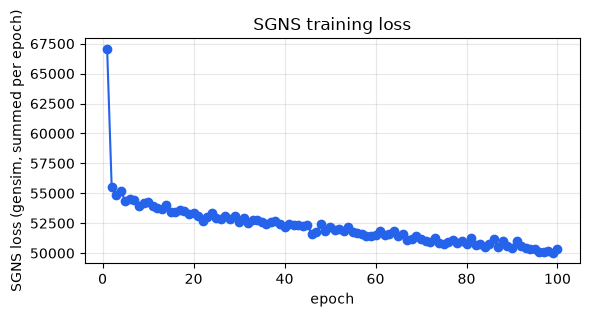

In [144]:
import matplotlib
matplotlib.rcParams["axes.unicode_minus"] = False
import matplotlib.pyplot as plt

eps_, ls_ = [h[0] for h in history], [h[1] for h in history]
plt.figure(figsize=(6, 3.2))
plt.plot(eps_, ls_, marker="o", color="#2563EB")
plt.xlabel("epoch"); plt.ylabel("SGNS loss (gensim, summed per epoch)")
plt.title("SGNS training loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [145]:
for probe in ["rice", "coffee", "doctor", "university", "student"]:
    print(f"Nearest neighbours of '{probe}' (word2vec SGNS):")
    for w, s in w2v.wv.most_similar(probe, topn=5):
        print(f"   {w:<14} {s:.4f}")
    print()

Nearest neighbours of 'rice' (word2vec SGNS):
   soup           0.9736
   cake           0.9701
   salad          0.9683
   omelette       0.9603
   noodles        0.9478

Nearest neighbours of 'coffee' (word2vec SGNS):
   juice          0.9780
   milk           0.9726
   tea            0.9616
   water          0.9599
   breakfast      0.4375

Nearest neighbours of 'doctor' (word2vec SGNS):
   nurse          0.9052
   programmer     0.5858
   lecturer       0.5787
   chef           0.5659
   engineer       0.5559

Nearest neighbours of 'university' (word2vec SGNS):
   factory        0.6261
   school         0.5782
   hospital       0.5710
   restaurant     0.5251
   office         0.4964

Nearest neighbours of 'student' (word2vec SGNS):
   lecturer       0.9683
   chef           0.6413
   engineer       0.6212
   pupil          0.5886
   nurse          0.5765

